In [1]:
!pip install -U diffusers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 29.0 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: diffusers
    Found existing installation: diffusers 0.42.0
    Uninstalling diffusers-0.42.0:
      Successfully uninstalled diffusers-0.42.0


## Local Inference on GPU 
Model page: https://huggingface.co/black-forest-labs/FLUX.2-klein-4B

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/black-forest-labs/FLUX.2-klein-4B)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [ ]:
pip install -U diffusers transformers accelerate

In [2]:
!pip install -U git+https://github.com/huggingface/diffusers.git transformers accelerate

  Cloning https://github.com/huggingface/diffusers.git to /tmp/pip-req-build-ebax_ni0
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/diffusers.git /tmp/pip-req-build-ebax_ni0
  Resolved https://github.com/huggingface/diffusers.git to commit 16eb5cc4fd8262fd33b3c9119a12977c25cc4985
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 43.3 MB/s  0:00:00eta 0:00:01
  Created wheel for diffusers: filename=diffusers-0.44.0.dev0-py3-none-any.whl size=6544774 sha256=db70869e9aada9621b945fb0053cec5d56e0209a80c49b48e71e448ff06eb2bd
  Stored in directory: /tmp/pip-ephem-wheel-cache-3gfju2_p/wheels/16/f5/67/8b5e8d211f82c13384f5cd17d760f2df2fc61184f775119f20
Successfully built diffusers
  Attempting uninstall: diffusers
    Found existing installation: diffusers 0.43.0
    Uninstalling diffusers-0.43.0:
      Successfully 

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


GPU: Tesla T4
Free VRAM: 14.46 GB


model_index.json:   0%|          | 0.00/446 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


FLUX.2 Klein loaded with sequential offloading!
Input resolution: (384, 256)


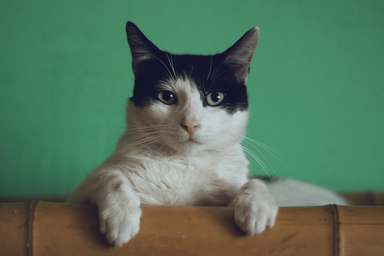

  0%|          | 0/4 [00:00<?, ?it/s]

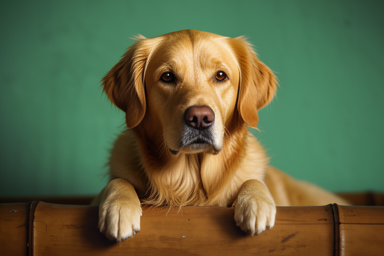

Image editing completed!
Output resolution: (384, 256)


In [3]:

import torch
import gc
from PIL import Image
from diffusers import Flux2KleinPipeline
from diffusers.utils import load_image
from IPython.display import display

# ==========================================
# 1. CLEAN GPU MEMORY
# ==========================================

for var_name in [
    "pipe", "base_pipe", "result",
    "output_image", "image", "input_image"
]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print("GPU:", torch.cuda.get_device_name(0))
print("Free VRAM:",
      round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

# ==========================================
# 2. LOAD FLUX.2 KLEIN 4B
# ==========================================

# FP16 is appropriate for Tesla T4
pipe = Flux2KleinPipeline.from_pretrained(
    "black-forest-labs/FLUX.2-klein-4B",
    dtype=torch.float16,
    use_safetensors=True
)

# Maximum VRAM savings
pipe.enable_sequential_cpu_offload()

print("FLUX.2 Klein loaded with sequential offloading!")

# ==========================================
# 3. LOAD INPUT IMAGE
# ==========================================

input_image = load_image(
    "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png"
).convert("RGB")

# Resize while preserving aspect ratio
max_side = 384
scale = min(1.0, max_side / max(input_image.size))

new_width = max(16, int(input_image.width * scale) // 16 * 16)
new_height = max(16, int(input_image.height * scale) // 16 * 16)

input_image = input_image.resize(
    (new_width, new_height),
    Image.Resampling.LANCZOS
)

print("Input resolution:", input_image.size)
display(input_image)

# ==========================================
# 4. IMAGE EDITING
# ==========================================

prompt = """
Transform this cat into a realistic golden retriever dog.
Preserve the original composition, camera angle and background.
Natural golden fur, realistic anatomy, detailed eyes,
professional photography, cinematic lighting.
"""

with torch.inference_mode():
    result = pipe(
        image=input_image,
        prompt=prompt,
        num_inference_steps=4,
        guidance_scale=1.0
    )

output_image = result.images[0]

# ==========================================
# 5. SAVE OUTPUT
# ==========================================

display(output_image)

output_image.save("flux2_klein_t4_output.png")

print("Image editing completed!")
print("Output resolution:", output_image.size)

gc.collect()
torch.cuda.empty_cache()
